### Mouse neuroblastoma (Exp201 SPC331): pixel clustering on the AnnOverview training crop
Same ROI as the round-1 training image in AnnOverview (`exp201_y6144_x2048`): slide pixels y 6144-7168, x 2048-3072 (1024 x 1024, 0.17 um/px)
so the clusters can be compared with the corrected cell masks (`masks.tif`).

In [1]:
from pathlib import Path
import numpy as np, tifffile
import spatialdata as sd
from spatialdata.models import Image2DModel

SLIDE = Path("~/Documents/annoloop_demo_images/whole_slide/Exp201_SPC331_261014_AVH_SUBSET_SingleTiff.tif").expanduser()
Y0, Y1, X0, X1 = 6144, 7168, 2048, 3072          # region from AnnOverview's annotation.json
CHANNEL_NAMES = ["DAPI", "NaK_ATPase", "F480", "autofluo_FITC", "autofluo_PE", "autofluo_APC"]   # order given in the demo README

with tifffile.TiffFile(SLIDE) as tf:             # one page per channel; crop each page
    arr = np.stack([pg.asarray()[Y0:Y1, X0:X1] for pg in tf.pages])
print(arr.shape, arr.dtype)

(6, 1024, 1024) uint16


In [2]:
img = Image2DModel.parse(
    arr,
    dims=("c", "y", "x"),            # TIFF axes are CYX
    c_coords=CHANNEL_NAMES,
    scale_factors=[2, 2],
)

sdata = sd.SpatialData(images={"ROI1": img})
print(sdata)

SpatialData object
└── Images
      └── 'ROI1': DataTree[cyx] (6, 1024, 1024), (6, 512, 512), (6, 256, 256)
with coordinate systems:
    ▸ 'global', with elements:
        ROI1 (Images)


### Pixel clustering: Harpy preprocessing + FlowSOM
Clusters use DAPI, NaK_ATPase and F480; the three autofluorescence channels are left out.

In [3]:
import dask
dask.config.set(scheduler="synchronous")   # FlowSOM uses numba, which crashes when dask threads call it concurrently

import harpy as hp

EXCLUDE = ["autofluo_FITC", "autofluo_PE", "autofluo_APC"]   # cluster on DAPI, NaK_ATPase, F480 only
CHANNELS = [c for c in CHANNEL_NAMES if c not in EXCLUDE]
N_METACLUSTERS = 8

sdata = hp.im.pixel_clustering_preprocess(
    sdata,
    image_name="ROI1",
    output_image_name="ROI1_pre",
    channels=CHANNELS,
    overwrite=True,
)

sdata, fsom, mapping = hp.im.flowsom(
    sdata,
    image_name="ROI1_pre",
    output_cluster_labels_name="ROI1_som",
    output_metacluster_labels_name="ROI1_meta",
    channels=CHANNELS,
    fraction=0.2,                 # fraction of pixels used for training; prediction runs on all pixels
    n_clusters=N_METACLUSTERS,
    write_intermediate=False,      # sdata is not backed by a zarr store
    overwrite=True,
)

2026-11-17 15:06:51.541 +01:00 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'ROI1_pre'
2026-11-17 15:06:52.881 +01:00 | INFO     | harpy.image.pixel_clustering._clustering:flowsom:161 - Extracting random sample for FlowSOM training.
2026-11-17 15:06:52.885 +01:00 | INFO     | harpy.image.pixel_clustering._clustering:_sample_dask_array:398 - Start sampling
2026-11-17 15:06:53.014 +01:00 | INFO     | harpy.image.pixel_clustering._clustering:flowsom:219 - Start FlowSOM training.
2026-11-17 15:06:53.019 +01:00 | DEBUG    | flowsom.main:__init__:82 - Reading input.
2026-11-17 15:06:53.020 +01:00 | DEBUG    | flowsom.main:__init__:84 - Fitting model: clustering and metaclustering.
2026-11-17 15:06:54.720 +01:00 | DEBUG    | flowsom.main:__init__:86 - Updating derived values.
2026-11-17 15:06:55.018 +01:00 | INFO     | harpy.image.pixel_clustering._clustering:flowsom:221 - Finished FlowSOM training. Starting inference 
2026-11-17 15:06:55.481 +01:00 | INFO    

### Mean signal per cluster
`hp.tb.cluster_intensity_SOM` fails with the installed pandas, so the per-cluster means are computed here directly (chunk by chunk, so the image is never fully in memory).

In [4]:
import numpy as np, pandas as pd

def level0(el):
    """Full-resolution array of an image/labels element (handles multiscale)."""
    return sd.get_pyramid_levels(el, n=0) if hasattr(el, "keys") else el

pre = level0(sdata.images["ROI1_pre"])
som = level0(sdata.labels["ROI1_som"])
names = list(pre.coords["c"].values)
n_ids = int(mapping.index.max()) + 1

def cluster_sums(img, lab, n_ids):
    """Per-SOM-cluster sum of every channel + pixel count; label 0 (masked pixels) is dropped later."""
    img = img.data.rechunk({0: -1})
    lab = lab.data.rechunk(img.chunks[1:])
    n_c = img.shape[0]
    def blk(x, l):
        x = np.nan_to_num(np.asarray(x, dtype=np.float64))
        l = np.asarray(l).astype(np.int64).ravel()
        sums = np.stack([np.bincount(l, weights=x[c].ravel(), minlength=n_ids) for c in range(n_c)], axis=1)
        return sums, np.bincount(l, minlength=n_ids)
    parts = [dask.delayed(blk)(img.blocks[:, i, j], lab.blocks[i, j])
             for i in range(img.numblocks[1]) for j in range(img.numblocks[2])]
    res = dask.compute(*parts)
    return sum(r[0] for r in res), sum(r[1] for r in res)

sums, counts = cluster_sums(pre, som, n_ids)

keep = np.array([i for i in mapping.index if counts[i] > 0])          # SOM clusters that contain pixels
som_mean = pd.DataFrame(sums[keep] / counts[keep, None], index=keep, columns=names)
som_n = pd.Series(counts[keep], index=keep)
meta_of = mapping.loc[keep]

meta_sums = pd.DataFrame(sums[keep], index=keep, columns=names).groupby(meta_of.values).sum()
meta_n = som_n.groupby(meta_of.values).sum()
meta_mean = meta_sums.div(meta_n, axis=0)                              # pixel-weighted mean per metacluster
print(meta_mean.shape, "metaclusters x channels")

(8, 3) metaclusters x channels


### Heatmap: signal per metacluster
Colour = z-scored mean intensity of each marker across metaclusters (clipped to +/-3). The coloured strip on the left is the metacluster colour used in the images below.

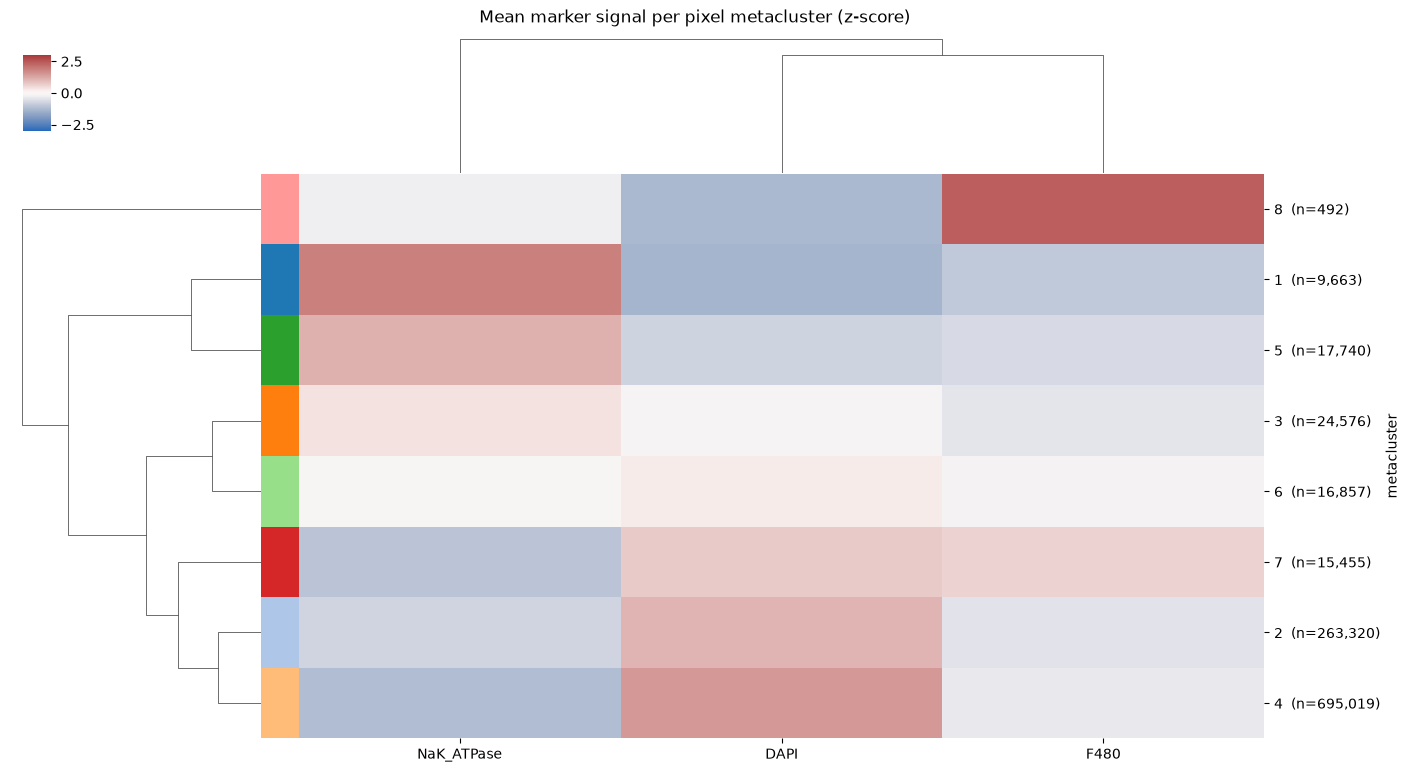

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ids = list(meta_mean.index)
pal = sns.color_palette("tab20", 20) if len(ids) <= 20 else sns.color_palette("hls", len(ids))
meta_color = {k: pal[i % len(pal)] for i, k in enumerate(ids)}

z = (meta_mean - meta_mean.mean()) / meta_mean.std(ddof=0).replace(0, 1)
z = z.clip(-3, 3).fillna(0)
z.index = [f"{k}  (n={meta_n[k]:,})" for k in ids]

g = sns.clustermap(
    z, cmap="vlag", center=0, vmin=-3, vmax=3,
    row_colors=[meta_color[k] for k in ids], metric="euclidean", method="average",
    figsize=(14, 0.45 * len(ids) + 4), cbar_pos=(0.02, 0.85, 0.02, 0.1),
    xticklabels=True, yticklabels=True,
)
g.ax_heatmap.set_ylabel("metacluster")
g.fig.suptitle("Mean marker signal per pixel metacluster (z-score)", y=1.01)
plt.show()

### Image: each pixel coloured by its cluster
Left: the real image (3 markers as RGB). Middle: every pixel coloured by metacluster (black = masked/background pixels). Right: overlay.

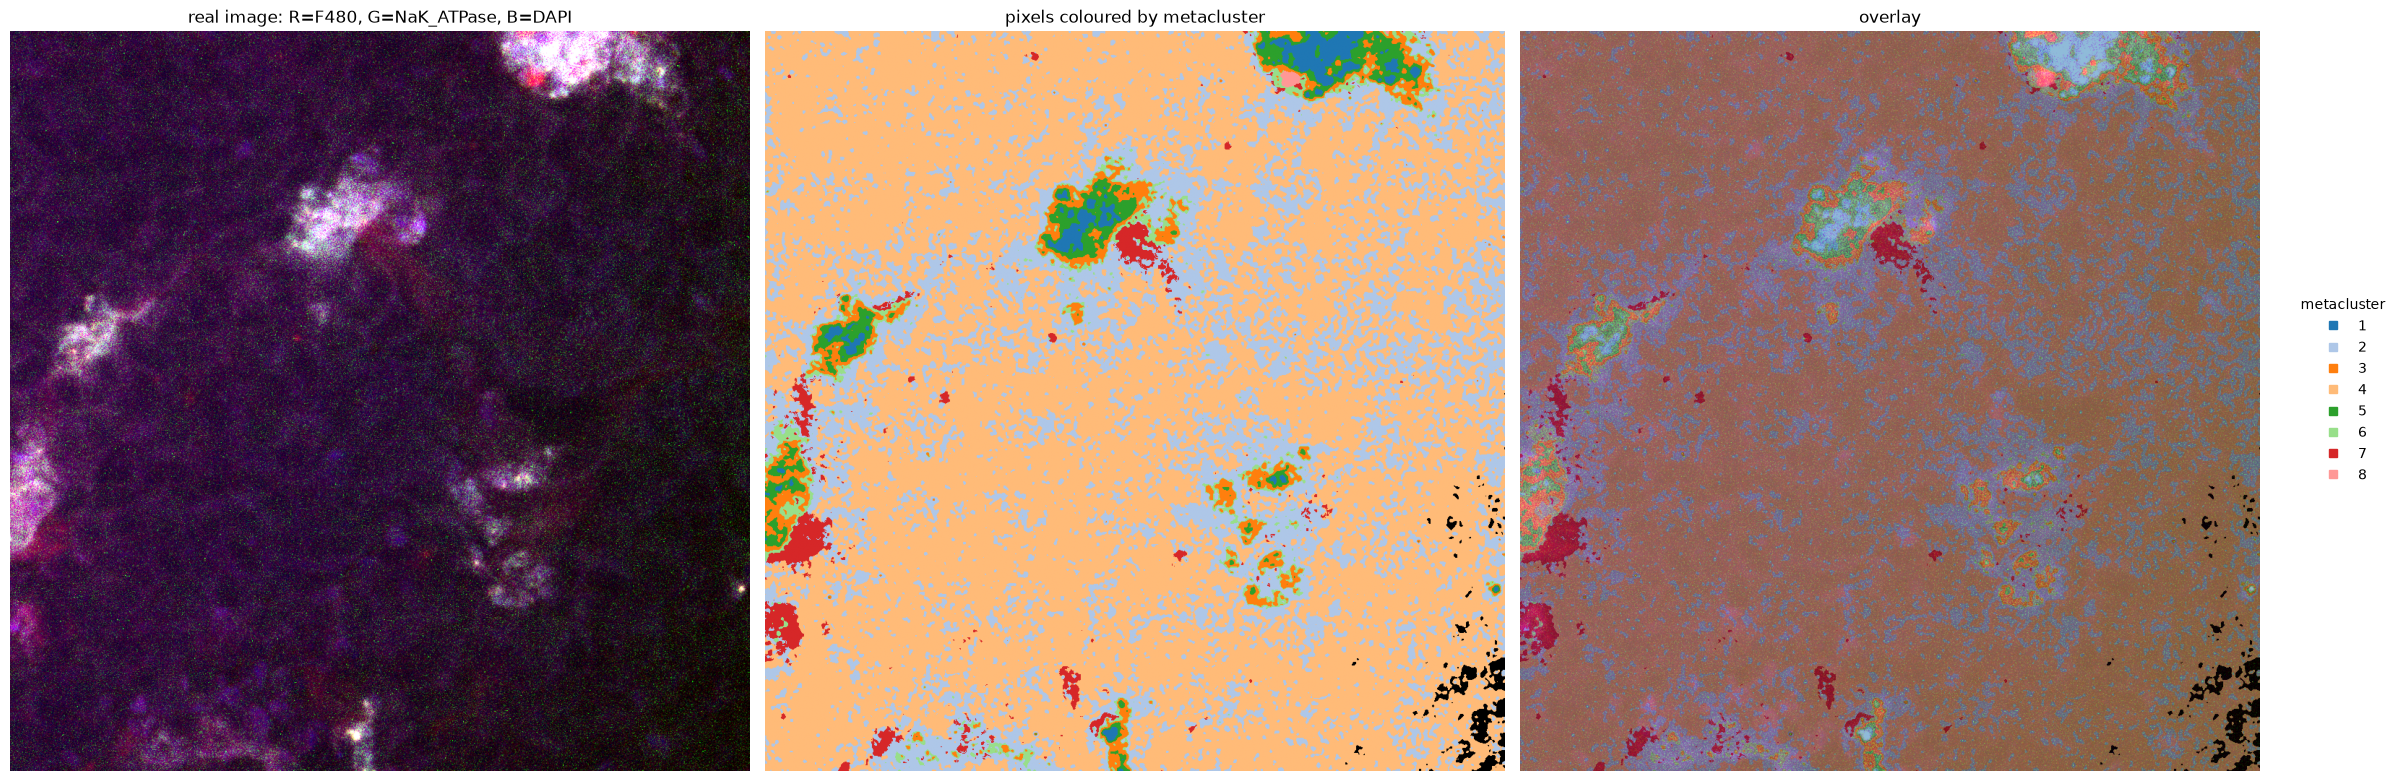

: 

In [ ]:
# markers shown as R, G, B in the real image (edit to taste)
SHOW = {"R": "F480", "G": "NaK_ATPase", "B": "DAPI"}

raw = level0(sdata.images["ROI1"])
meta = level0(sdata.labels["ROI1_meta"])
H, W = meta.shape
step = max(1, max(H, W) // 2500)                       # downsample for display only

def norm(a):
    lo, hi = np.percentile(a, [1, 99.5])
    return np.clip((a - lo) / max(hi - lo, 1e-9), 0, 1)

rgb_raw = np.dstack([norm(raw.sel(c=SHOW[k]).data[::step, ::step].compute().astype(np.float32)) for k in "RGB"])

meta_small = meta.data[::step, ::step].compute().astype(np.int64)
lut = np.zeros((max(max(ids), int(meta_small.max())) + 1, 3))      # id 0 -> black
for k, col in meta_color.items():
    lut[k] = col
rgb_cl = lut[meta_small]

fig, ax = plt.subplots(1, 3, figsize=(24, 8), sharex=True, sharey=True)
ax[0].imshow(rgb_raw);  ax[0].set_title("real image: " + ", ".join(f"{k}={SHOW[k].split()[0]}" for k in "RGB"))
ax[1].imshow(rgb_cl);   ax[1].set_title("pixels coloured by metacluster")
ax[2].imshow(rgb_raw);  ax[2].imshow(rgb_cl, alpha=0.5);  ax[2].set_title("overlay")
for a in ax:
    a.axis("off")
handles = [plt.Line2D([], [], marker="s", ls="", color=meta_color[k], label=f"{k}") for k in ids]
fig.legend(handles=handles, title="metacluster", loc="center right", ncol=1, frameon=False)
plt.tight_layout(rect=(0, 0, 0.95, 1))
plt.show()